In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import datetime as dt
import ipywidgets as widgets
from IPython.display import display

In [4]:
from pathlib import Path
data_path = Path('../data/deals_all_opt_2026-09-11__risk_uniform.csv')
df = pd.read_csv(data_path)

In [3]:
df.head()

,strategy_name,signal_type,instrument,timeframe,direction,entry_date,entry_price,stop_price,exit_date,exit_price,exit_type,old_volume,old_start_equity,volume,commission,profit_abs,profit_eq_pc,start_equity
0,ETH-USDT-SWAP_H4_STOCH_False_True_False_w,STOCH,ETH-USDT-SWAP,H4,Short,2021-01-01 20:00:00,725.06,756.23,2021-01-02 12:00:00,756.28,stop,3.208,10000.000000,0.075,0.055550,-2.397050,-0.023971,10000.000000
1,ETH-USDT-SWAP_H4_EXPANSION_False_True_False_w,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-02 04:00:00,734.59,715.11,2021-01-02 08:00:00,735.61,take_profit,5.133,10000.000000,0.121,0.088947,0.034473,0.000345,10000.000000
2,ETH-USDT-SWAP_H4_EXPANSION_False_True_False,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-02 04:00:00,734.59,715.11,2021-01-02 08:00:00,735.61,take_profit,5.133,10000.000000,0.121,0.088947,0.034473,0.000345,10000.000000
3,ETH-USDT-SWAP_H4_EXPANSION_False_True_False,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-03 08:00:00,807.48,769.19,2021-01-03 12:00:00,830.26,take_profit,2.612,10001.462392,0.061,0.049951,1.339629,0.013399,9997.671896
4,ETH-USDT-SWAP_H4_EXPANSION_False_True_False_w,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-03 08:00:00,807.48,769.19,2021-01-03 12:00:00,830.26,take_profit,2.612,10001.462392,0.061,0.049951,1.339629,0.013399,9997.671896


In [4]:
df[['volume', 'entry_price', 'exit_price', 'commission', 'profit_abs']].head()

,volume,entry_price,exit_price,commission,profit_abs
0,0.075,725.06,756.28,0.055550,-2.397050
1,0.121,734.59,735.61,0.088947,0.034473
2,0.121,734.59,735.61,0.088947,0.034473
3,0.061,807.48,830.26,0.049951,1.339629
4,0.061,807.48,830.26,0.049951,1.339629


In [5]:
df.describe()

,entry_price,stop_price,exit_price,old_volume,old_start_equity,volume,commission,profit_abs,profit_eq_pc,start_equity
count,60125.000000,60125.000000,60125.000000,6.012500e+04,60125.000000,6.012500e+04,60125.000000,60125.000000,60125.000000,60125.000000
mean,2991.894646,2984.540383,2995.946239,4.281805e+07,40902.202665,6.887718e+06,2.159897,7.797108,0.007052,169737.788371
std,11269.392164,11226.904794,11296.106506,5.301147e+08,54790.147450,9.129632e+07,3.300467,147.590568,0.067035,175719.382286
min,0.000004,0.000004,0.000004,1.910000e-02,8071.640881,4.000000e-04,0.002365,-505.196690,-0.111542,9650.351026
25%,2.436050,2.440500,2.431250,4.983000e+00,15804.071824,4.170000e-01,0.234907,-29.836220,-0.024960,29667.153909
50%,194.190000,194.210000,193.385000,5.528000e+01,26346.469983,3.165000e+00,0.941276,-4.625309,-0.023908,78063.012033
75%,2409.800000,2403.220000,2409.950000,4.750000e+03,42606.654560,4.281000e+02,2.708784,5.458995,0.004020,303304.542902
max,125800.500000,125386.500000,125513.500000,2.363020e+10,594294.763352,3.453700e+09,83.356290,6612.568512,1.596735,557049.018861


In [6]:
df[['entry_date', 'exit_date']].dtypes

entry_date    str
exit_date     str
dtype: object

In [7]:
df['entry_date'] = pd.to_datetime(df['entry_date'])
df['exit_date'] = pd.to_datetime(df['exit_date'])

In [8]:
df[['entry_date', 'exit_date']]

,entry_date,exit_date
0,2021-01-01 20:00:00,2021-01-02 12:00:00
1,2021-01-02 04:00:00,2021-01-02 08:00:00
2,2021-01-02 04:00:00,2021-01-02 08:00:00
3,2021-01-03 08:00:00,2021-01-03 12:00:00
4,2021-01-03 08:00:00,2021-01-03 12:00:00
...,...,...
60120,2026-09-11 14:30:00,2026-09-11 17:00:00
60121,2026-09-11 15:00:00,2026-09-11 17:00:00
60122,2026-09-11 15:30:00,2026-09-11 17:00:00
60123,2026-09-11 16:00:00,2026-09-11 17:00:00


In [9]:
df_sorted = df.sort_values(by='exit_date').reset_index(drop=True)

In [10]:
df_sorted.head()

,strategy_name,signal_type,instrument,timeframe,direction,entry_date,entry_price,stop_price,exit_date,exit_price,exit_type,old_volume,old_start_equity,volume,commission,profit_abs,profit_eq_pc,start_equity
0,ETH-USDT-SWAP_H4_EXPANSION_False_True_False_w,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-02 04:00:00,734.59,715.11,2021-01-02 08:00:00,735.61,take_profit,5.133,10000.000000,0.121,0.088947,0.034473,0.000345,10000.000000
1,ETH-USDT-SWAP_H4_EXPANSION_False_True_False,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-02 04:00:00,734.59,715.11,2021-01-02 08:00:00,735.61,take_profit,5.133,10000.000000,0.121,0.088947,0.034473,0.000345,10000.000000
2,ETH-USDT-SWAP_H4_STOCH_False_True_False_w,STOCH,ETH-USDT-SWAP,H4,Short,2021-01-01 20:00:00,725.06,756.23,2021-01-02 12:00:00,756.28,stop,3.208,10000.000000,0.075,0.055550,-2.397050,-0.023971,10000.000000
3,ETH-USDT-SWAP_H4_EXPANSION_False_True_False,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-03 08:00:00,807.48,769.19,2021-01-03 12:00:00,830.26,take_profit,2.612,10001.462392,0.061,0.049951,1.339629,0.013399,9997.671896
4,ETH-USDT-SWAP_H4_EXPANSION_False_True_False_w,EXPANSION,ETH-USDT-SWAP,H4,Long,2021-01-03 08:00:00,807.48,769.19,2021-01-03 12:00:00,830.26,take_profit,2.612,10001.462392,0.061,0.049951,1.339629,0.013399,9997.671896


In [11]:
exit_profit = int((df['profit_abs'] > 0).sum())
print(exit_profit)

exit_loss = int((df['profit_abs'] < 0).sum())
print(exit_loss)

23367
36758


### Процент прибыльных и убыточных сделок

In [12]:
winrate = (exit_profit / (exit_profit + exit_loss)) * 100
print(f'win: {round(winrate)} %')
print(f'lose: {round(100-winrate)} %')

win: 39 %
lose: 61 %


### Средний абсолютный результат прибыльных и убыточных сделок

In [13]:
avg_win = float(df.loc[df['profit_abs'] > 0, 'profit_abs'].mean())
print(round(avg_win, 3))

84.544


In [14]:
avg_lose = float(abs(df.loc[df['profit_abs'] < 0, 'profit_abs'].mean()))
print(round(avg_lose, 3))

40.991


In [15]:
risk_reward = avg_win / avg_lose
risk_reward

2.06251330068008

In [16]:
p_win = winrate / 100  
p_lose = 1 - p_win     
E_abs = (p_win * avg_win) - (p_lose * avg_lose)
E_abs

7.797107826000914

### Процент сделок на покупку и продажу

In [17]:
long_c = int((df_sorted['direction'] == 'Long').sum())
print(long_c)
short_c = int((df_sorted['direction'] == 'Short').sum())
print(short_c)

print(f'long: {round(long_c /  (short_c + long_c) * 100)}%')
print(f'short: {round(100 - (long_c /  (short_c + long_c) * 100))}%')

28101
32024
long: 47%
short: 53%


### Максимальная прибыльная и убыточная сделки

In [18]:
print(df_sorted['profit_abs'].max())
print(df_sorted['profit_abs'].min())

6612.568512199999
-505.1966904999997


### Частота сделок (год,месяц,неделя) 

In [19]:
yearly_counts = df_sorted['entry_date'].dt.year.value_counts().sort_index()
print(yearly_counts)
print(df_sorted['entry_date'].dt.year.unique())

entry_date
2021     9098
2022    10678
2023    10644
2024    10619
2025    11116
2026     7970
Name: count, dtype: int64
[2021 2022 2023 2024 2025 2026]


In [20]:
month_counts = df_sorted['entry_date'].dt.to_period('W').value_counts().sort_index()
# print(month_counts)

In [21]:
week_counts = df_sorted['entry_date'].dt.to_period('W').value_counts()
# print(week_counts)

### Денежная кривая реализованного баланса портфеля

In [22]:
start_balance = float(df.sort_values('entry_date')['start_equity'].iloc[0])
portfolio_start_date = df['entry_date'].min()
portfolio_end_date = df_sorted['exit_date'].max()
last_observation_date = portfolio_end_date
last_year_is_complete = last_observation_date.month == 12 and last_observation_date.day == 31
portfolio_calendar = pd.date_range(portfolio_start_date.normalize(), portfolio_end_date.normalize(), freq='D')
closed_pnl = df_sorted.groupby('exit_date')['profit_abs'].sum().sort_index()
cumulative_cash_pnl = closed_pnl.cumsum()
df_sorted['cum_pnl_abs'] = cumulative_cash_pnl.reindex(df_sorted['exit_date']).to_numpy()
df_sorted['balance_simple'] = start_balance + df_sorted['cum_pnl_abs']
portfolio_daily_pnl = closed_pnl.resample('D').sum().reindex(portfolio_calendar, fill_value=0.0)
portfolio_daily_balance = start_balance + portfolio_daily_pnl.cumsum()
portfolio_previous_balance = portfolio_daily_balance.shift(1, fill_value=start_balance)
daily_returns = portfolio_daily_pnl / portfolio_previous_balance

In [23]:
print('Первые закрытия:')
display(df_sorted[['exit_date', 'profit_abs', 'balance_simple']].head(3))
print('Последние закрытия:')
display(df_sorted[['exit_date', 'profit_abs', 'balance_simple']].tail(3))

Первые закрытия:


,exit_date,profit_abs,balance_simple
0,2021-01-02 08:00:00,0.034473,10000.068946
1,2021-01-02 08:00:00,0.034473,10000.068946
2,2021-01-02 12:00:00,-2.397050,9997.671896


Последние закрытия:


,exit_date,profit_abs,balance_simple
60122,2026-09-11 17:15:00,-87.837157,478733.871928
60123,2026-09-11 17:30:00,39.629615,478801.108038
60124,2026-09-11 17:30:00,27.606495,478801.108038


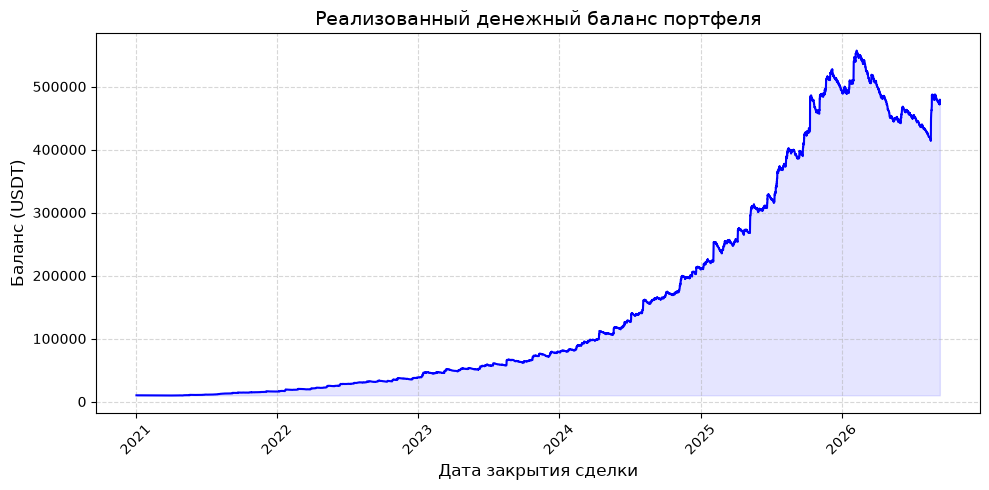

In [24]:
plt.figure(figsize=(10,5))
plt.plot(df_sorted['exit_date'], df_sorted['balance_simple'], color='blue', linewidth=1.5)
plt.title('Реализованный денежный баланс портфеля', fontsize=14)
plt.xlabel('Дата закрытия сделки', fontsize=12)
plt.ylabel('Баланс (USDT)', fontsize=12)
plt.grid(True, alpha=0.5, linestyle='--')

plt.fill_between(df_sorted['exit_date'], df_sorted['balance_simple'], start_balance, alpha=0.1, color='blue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Накопленный денежный PnL по годам

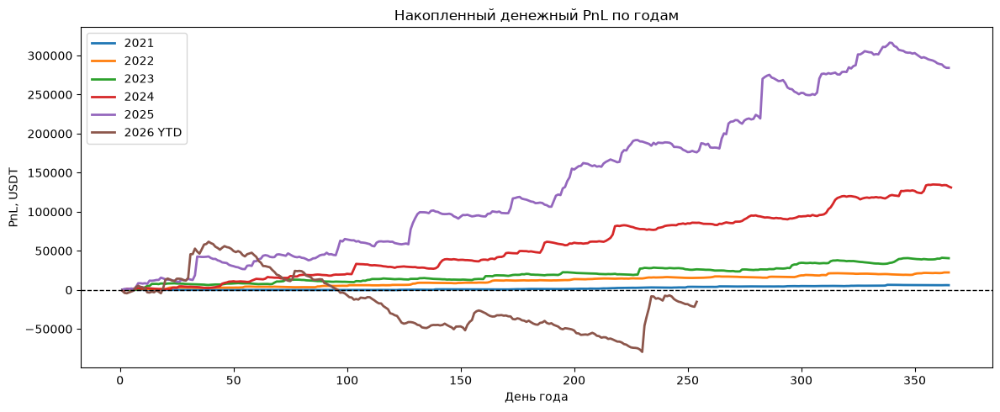

In [25]:
years = sorted(portfolio_daily_pnl.index.year.unique())
plt.figure(figsize=(12, 5))
for year in years:
    pnl = portfolio_daily_pnl.loc[portfolio_daily_pnl.index.year == year]
    year_label = f'{year} YTD' if year == last_observation_date.year and not last_year_is_complete else str(year)
    plt.plot(pnl.index.dayofyear, pnl.cumsum(), label=year_label, linewidth=2)
plt.title('Накопленный денежный PnL по годам')
plt.xlabel('День года')
plt.ylabel('PnL, USDT')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.legend()
plt.tight_layout()
plt.show()

### Относительная просадка реализованного баланса портфеля

In [26]:
df_sorted['peak_balance_simple'] = df_sorted['balance_simple'].cummax().clip(lower=start_balance)
df_sorted['drawdown_equity_pct'] = (df_sorted['balance_simple'] / df_sorted['peak_balance_simple'] - 1) * 100
max_drawdown_equity_pct = -df_sorted['drawdown_equity_pct'].min()
print(f'MDD реализованного баланса портфеля: {max_drawdown_equity_pct:.2f}%')

MDD реализованного баланса портфеля: 25.66%


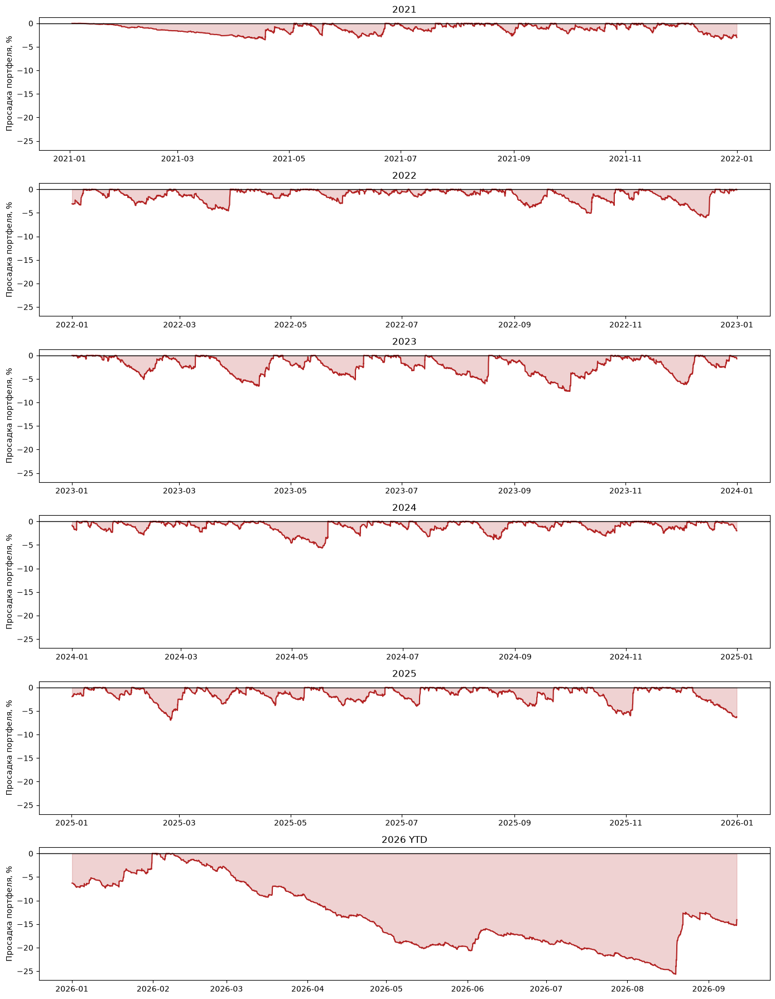

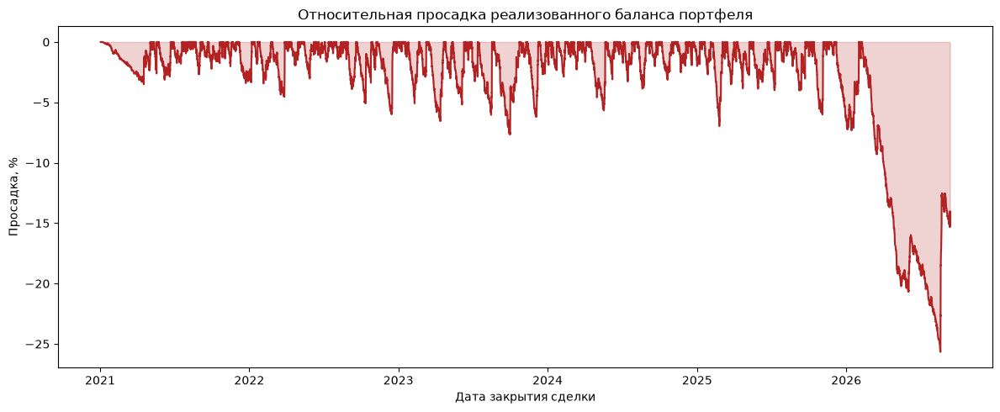

In [27]:
fig, axes = plt.subplots(len(years), 1, figsize=(14, 18), sharey=True, squeeze=False)
for ax, year in zip(axes[:, 0], years):
    yearly = df_sorted.loc[df_sorted['exit_date'].dt.year == year]
    ax.plot(yearly['exit_date'], yearly['drawdown_equity_pct'], color='firebrick')
    ax.fill_between(yearly['exit_date'], yearly['drawdown_equity_pct'], 0, color='firebrick', alpha=0.2)
    year_label = f'{year} YTD' if year == last_observation_date.year and not last_year_is_complete else str(year)
    ax.set(title=year_label, ylabel='Просадка портфеля, %')
    ax.axhline(0, color='black', linewidth=1)
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 5))
plt.plot(df_sorted['exit_date'], df_sorted['drawdown_equity_pct'], color='firebrick')
plt.fill_between(df_sorted['exit_date'], df_sorted['drawdown_equity_pct'], 0, color='firebrick', alpha=0.2)
plt.title('Относительная просадка реализованного баланса портфеля')
plt.xlabel('Дата закрытия сделки')
plt.ylabel('Просадка, %')
plt.tight_layout()
plt.show()

### Денежный PnL по периодам: полные годы и текущий год YTD

In [28]:
weekly_pnl = portfolio_daily_pnl.resample('W').sum()
monthly_pnl = portfolio_daily_pnl.resample('ME').sum()
annual_pnl = portfolio_daily_pnl.resample('YE').sum()
annual_pnl_complete = annual_pnl.loc[annual_pnl.index.year < last_observation_date.year] if not last_year_is_complete else annual_pnl.copy()
annual_pnl_ytd = annual_pnl.loc[annual_pnl.index.year == last_observation_date.year] if not last_year_is_complete else pd.Series(dtype=float)
print(f'Средний недельный PnL: {weekly_pnl.mean():,.2f} USDT')
print(f'Стандартное отклонение недельного PnL: {weekly_pnl.std():,.2f} USDT')

Средний недельный PnL: 1,573.16 USDT
Стандартное отклонение недельного PnL: 8,446.06 USDT


In [29]:
print(f'Средний месячный PnL: {monthly_pnl.mean():,.2f} USDT')
print(f'Стандартное отклонение месячного PnL: {monthly_pnl.std():,.2f} USDT')

Средний месячный PnL: 6,794.22 USDT
Стандартное отклонение месячного PnL: 16,225.50 USDT


In [30]:
print(f'Средний годовой денежный PnL по полным годам: {annual_pnl_complete.mean():,.2f} USDT')
print(f'Стандартное отклонение по полным годам: {annual_pnl_complete.std():,.2f} USDT')
if not annual_pnl_ytd.empty:
    print(f'{last_observation_date.year} YTD: {annual_pnl_ytd.iloc[0]:,.2f} USDT')

Средний годовой денежный PnL по полным годам: 96,807.58 USDT
Стандартное отклонение по полным годам: 115,373.22 USDT
2026 YTD: -15,236.80 USDT


### Фактор восстановления и стандартный Calmar денежной кривой капитала

In [31]:
max_drawdown_abs = (df_sorted['peak_balance_simple'] - df_sorted['balance_simple']).max()
ending_balance = df_sorted['balance_simple'].iloc[-1]
total_net_profit_abs = ending_balance - start_balance
portfolio_years = len(portfolio_calendar) / 365.25
recovery_factor_equity = total_net_profit_abs / max_drawdown_abs if max_drawdown_abs > 0 else np.nan
cagr_pct = ((ending_balance / start_balance) ** (1 / portfolio_years) - 1) * 100
calmar_ratio = cagr_pct / max_drawdown_equity_pct if max_drawdown_equity_pct > 0 else np.nan
print(f'Начальный баланс: {start_balance:,.2f} USDT; конечный: {ending_balance:,.2f} USDT')
print(f'Recovery Factor: {recovery_factor_equity:.3f}; CAGR: {cagr_pct:.3f}%')
print(f'MDD: {max_drawdown_equity_pct:.3f}%; Calmar: {calmar_ratio:.3f}')

Начальный баланс: 10,000.00 USDT; конечный: 478,801.11 USDT
Recovery Factor: 3.280; CAGR: 97.259%
MDD: 25.659%; Calmar: 3.791


### Sharpe и Sortino по дневной доходности реализованного баланса

In [32]:
risk_free_daily = 0.0
excess_daily_returns = daily_returns - risk_free_daily
daily_return_std = excess_daily_returns.std()
sharpe_ratio = excess_daily_returns.mean() / daily_return_std * np.sqrt(365) if daily_return_std > 0 else np.nan
print(f'Sharpe портфеля: {sharpe_ratio:.3f}')

Sharpe портфеля: 3.534


In [50]:
downside_std = np.sqrt(np.mean(np.minimum(excess_daily_returns, 0) ** 2))
sortino_ratio = excess_daily_returns.mean() / downside_std * np.sqrt(365) if downside_std > 0 else np.nan
portfolio_metrics = pd.Series({
    'Начальный баланс, USDT': start_balance, 
    'Конечный баланс, USDT': ending_balance,
    'PnL, USDT': total_net_profit_abs,
    'MDD, %': max_drawdown_equity_pct,
    'CAGR, %': cagr_pct,
    'Calmar': calmar_ratio, 
    'Recovery Factor': recovery_factor_equity, 
    'Sharpe': sharpe_ratio,
    'Sortino': sortino_ratio})
display(portfolio_metrics.round(3))

Начальный баланс, USDT     10000.000
Конечный баланс, USDT     478801.108
PnL, USDT                 468801.108
MDD, %                        25.659
CAGR, %                       97.259
Calmar                         3.791
Recovery Factor                3.280
Sharpe                         3.534
Sortino                       13.672
dtype: float64

### Торговые пары

In [34]:
instruments = df_sorted['instrument'].unique()
instruments

<StringArray>
[ 'ETH-USDT-SWAP',  'SOL-USDT-SWAP', 'AAVE-USDT-SWAP', 'AVAX-USDT-SWAP',
 'DOGE-USDT-SWAP', 'EGLD-USDT-SWAP',  'BTC-USDT-SWAP',  'CFX-USDT-SWAP',
  'XLM-USDT-SWAP',  'UMA-USDT-SWAP',  'ONT-USDT-SWAP', 'BAND-USDT-SWAP',
  'RSR-USDT-SWAP',  'ADA-USDT-SWAP',  'FIL-USDT-SWAP',  'KSM-USDT-SWAP',
  'ZIL-USDT-SWAP',  'RVN-USDT-SWAP', 'SHIB-USDT-SWAP',  'IMX-USDT-SWAP',
   'OP-USDT-SWAP']
Length: 21, dtype: str

In [35]:
strategy_name = list(df_sorted['strategy_name'].unique())

# Анализ денежных вкладов отдельных стратегий

In [36]:
top_n, min_trades = 5, 100
rolling_window, rolling_min_periods, cdar_level = 250, 100, 0.95
serious_dd_threshold_usdt = start_balance * 0.005
strategy_columns = ['strategy_name', 'instrument', 'timeframe', 'direction', 'entry_date', 'exit_date', 'exit_type', 'profit_abs']
strategy_analysis = df_sorted[strategy_columns].sort_values(['strategy_name', 'exit_date'], kind='stable').copy()
strategy_events = strategy_analysis.groupby(['strategy_name', 'exit_date'])['profit_abs'].sum().sort_index()
strategy_event_curve = strategy_events.groupby(level='strategy_name').cumsum()
strategy_event_peak = strategy_event_curve.groupby(level='strategy_name').cummax().clip(lower=0)
strategy_event_drawdown = strategy_event_curve - strategy_event_peak

In [37]:
event_keys = pd.MultiIndex.from_frame(strategy_analysis[['strategy_name', 'exit_date']])
strategy_analysis['cum_profit_abs'] = strategy_event_curve.reindex(event_keys).to_numpy()
strategy_analysis['drawdown_usdt'] = strategy_event_drawdown.reindex(event_keys).to_numpy()
strategy_analysis['is_profitable'] = strategy_analysis['profit_abs'] > 0

In [38]:
strategy_summary = strategy_analysis.groupby('strategy_name').agg(net_pnl_usdt=('profit_abs', 'sum'), trades_count=('profit_abs', 'size'), max_drawdown_usdt=('drawdown_usdt', 'min'), win_rate_pct=('is_profitable', 'mean'), first_entry=('entry_date', 'min')).sort_values('net_pnl_usdt')
strategy_summary['max_drawdown_usdt'] = strategy_summary['max_drawdown_usdt'].abs()
strategy_summary['win_rate_pct'] *= 100
display(strategy_summary[['net_pnl_usdt', 'trades_count', 'max_drawdown_usdt', 'win_rate_pct']].round(3))

,net_pnl_usdt,trades_count,max_drawdown_usdt,win_rate_pct
strategy_name,,,,
SOL-USDT-SWAP_H1_MA_CND_CROSS_False_True_False,-511.983,975,7840.584,33.846
CFX-USDT-SWAP_M30_ENVELOPE_BREAKTHROUGH_False_True_True_w,-412.972,741,4055.657,29.690
AVAX-USDT-SWAP_H4_HHV_LLV_False_True_False_w,1494.725,410,5350.138,38.049
BTC-USDT-SWAP_M15_RISE_FALL_False_True_True,1530.250,384,3850.208,37.240
FIL-USDT-SWAP_H1_CONTRACTION_False_False_True_w,1608.488,386,3087.803,38.860
...,...,...,...,...
ETH-USDT-SWAP_H1_HHV_LLV_False_True_True_w,9598.919,811,4227.266,47.349
ETH-USDT-SWAP_H4_EXPANSION_False_False_True,9625.066,492,1379.979,48.577
ETH-USDT-SWAP_H1_HHV_LLV_False_True_False,11759.920,1005,5326.226,42.090


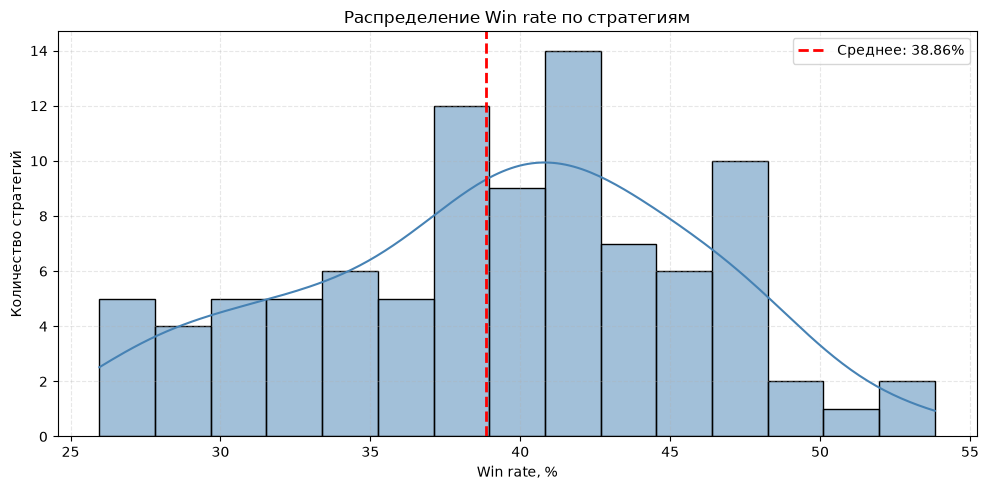

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(data=strategy_summary,x='win_rate_pct',bins=15,kde=True,color='steelblue')
plt.axvline(winrate,color='red',linestyle='--',linewidth=2,label=f'Среднее: {winrate:.2f}%')

plt.title('Распределение Win rate по стратегиям')
plt.xlabel('Win rate, %')
plt.ylabel('Количество стратегий')
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

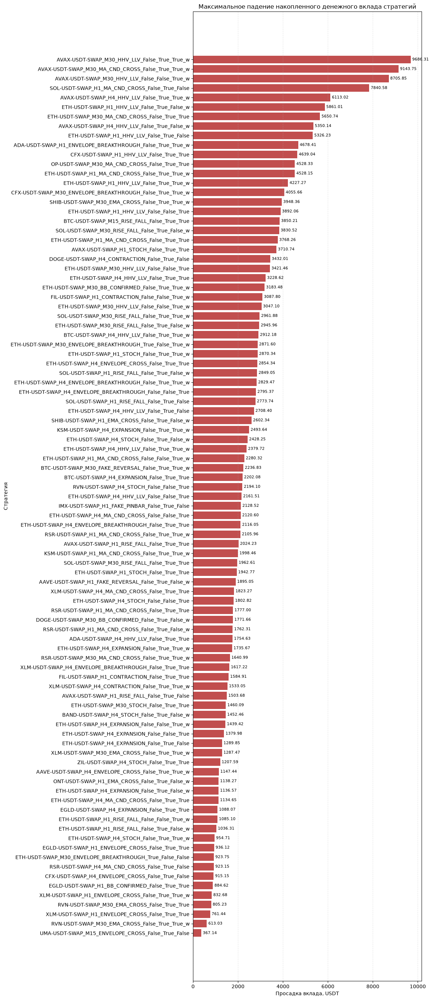

In [40]:
drawdown_by_strategy = strategy_summary['max_drawdown_usdt'].sort_values()
fig, ax = plt.subplots(figsize=(12, max(10, len(drawdown_by_strategy) * 0.3)))
bars = ax.barh(drawdown_by_strategy.index, drawdown_by_strategy, color='firebrick', alpha=0.8)
ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
ax.set(title='Максимальное падение накопленного денежного вклада стратегий', xlabel='Просадка вклада, USDT', ylabel='Стратегия')
ax.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [41]:
eligible_strategies = strategy_summary.query('trades_count >= @min_trades')
worst_strategies = eligible_strategies.head(top_n).index.tolist()
best_strategies = eligible_strategies.tail(top_n).index[::-1].tolist()

DaR/CDaR вкладов оцениваются по календарным дням; максимальная денежная просадка — по закрытиям с объединением одинакового времени. Rolling CDaR — последнее значение по 250 сделкам, минимум 100, с историческим пиком вклада. Порог серьёзной денежной просадки — 50 USDT (0,5% исходного капитала портфеля), это денежный порог, а не прежние −0,5 п.п. Годовой PnL вклада — линейная нормализация на длительность наблюдения; 2026 включён как неполный период.

In [42]:
strategy_daily_pnl = strategy_events.reset_index().assign(exit_day=lambda x: x['exit_date'].dt.normalize()).groupby(['exit_day', 'strategy_name'])['profit_abs'].sum().unstack('strategy_name').reindex(index=portfolio_calendar, columns=strategy_summary.index).fillna(0.0)
strategy_daily_curve = strategy_daily_pnl.cumsum()
strategy_daily_depth = strategy_daily_curve.cummax().clip(lower=0) - strategy_daily_curve
strategy_return_contributions = strategy_daily_pnl.div(portfolio_previous_balance, axis=0)
rolling_cdar = strategy_analysis.groupby('strategy_name')['drawdown_usdt'].rolling(window=rolling_window, min_periods=rolling_min_periods).apply(lambda x: (-x)[(-x) >= np.quantile(-x, cdar_level)].mean(), raw=True)
latest_rolling_cdar = rolling_cdar.groupby(level=0).last().rename('rolling_cdar_250_usdt')
all_metrics = strategy_summary.join(latest_rolling_cdar)
display(all_metrics)

,net_pnl_usdt,trades_count,max_drawdown_usdt,win_rate_pct,first_entry,rolling_cdar_250_usdt
strategy_name,,,,,,
SOL-USDT-SWAP_H1_MA_CND_CROSS_False_True_False,-511.982759,975,7840.583755,33.846154,2021-04-10 05:00:00,7511.605563
CFX-USDT-SWAP_M30_ENVELOPE_BREAKTHROUGH_False_True_True_w,-412.972238,741,4055.656606,29.689609,2021-04-14 09:30:00,3643.382870
AVAX-USDT-SWAP_H4_HHV_LLV_False_True_False_w,1494.724844,410,5350.137706,38.048780,2021-04-10 04:00:00,4829.082434
BTC-USDT-SWAP_M15_RISE_FALL_False_True_True,1530.250177,384,3850.208066,37.239583,2021-04-09 10:15:00,3325.666030
FIL-USDT-SWAP_H1_CONTRACTION_False_False_True_w,1608.488292,386,3087.803134,38.860104,2021-04-12 12:00:00,2603.137152
...,...,...,...,...,...,...
ETH-USDT-SWAP_H1_HHV_LLV_False_True_True_w,9598.919024,811,4227.266479,47.348952,2021-04-26 02:00:00,4089.861743
ETH-USDT-SWAP_H4_EXPANSION_False_False_True,9625.065760,492,1379.979250,48.577236,2021-01-05 16:00:00,908.600565
ETH-USDT-SWAP_H1_HHV_LLV_False_True_False,11759.919790,1005,5326.226356,42.089552,2021-04-06 01:00:00,5146.239195


In [43]:
for strategy_name in all_metrics.index:
    first_day = all_metrics.loc[strategy_name, 'first_entry'].normalize()
    depth = strategy_daily_depth.loc[first_day:, strategy_name]
    underwater = depth > 1e-10
    blocks = (~underwater).cumsum()
    contributions = strategy_return_contributions[strategy_name]
    std = contributions.std()
    downside = np.sqrt(np.mean(np.minimum(contributions, 0) ** 2))
    dar = depth.quantile(cdar_level)
    all_metrics.loc[strategy_name, 'DaR_95_usdt'] = dar
    all_metrics.loc[strategy_name, 'CDaR_95_usdt'] = depth[depth >= dar].mean()
    all_metrics.loc[strategy_name, 'Sharpe_contribution'] = contributions.mean() / std * np.sqrt(365) if std > 0 else np.nan
    all_metrics.loc[strategy_name, 'Sortino_contribution'] = contributions.mean() / downside * np.sqrt(365) if downside > 0 else np.nan
    all_metrics.loc[strategy_name, 'max_drawdown_duration_days'] = underwater.groupby(blocks).sum().max()
    all_metrics.loc[strategy_name, 'time_in_drawdown_calendar_pct'] = underwater.mean() * 100
    all_metrics.loc[strategy_name, 'serious_drawdown_days'] = (depth >= serious_dd_threshold_usdt).sum()
    all_metrics.loc[strategy_name, 'annualized_pnl_usdt'] = all_metrics.loc[strategy_name, 'net_pnl_usdt'] / (len(depth) / 365.25)


In [44]:
all_metrics['pnl_drawdown_ratio'] = all_metrics['net_pnl_usdt'] / all_metrics['max_drawdown_usdt'].replace(0, np.nan)
metrics = ['net_pnl_usdt', 'max_drawdown_usdt', 'DaR_95_usdt', 'CDaR_95_usdt', 'Sharpe_contribution', 'Sortino_contribution', 'pnl_drawdown_ratio', 'max_drawdown_duration_days', 'time_in_drawdown_calendar_pct', 'serious_drawdown_days', 'annualized_pnl_usdt', 'rolling_cdar_250_usdt']
metric_names = {'net_pnl_usdt': 'Итоговый PnL, USDT', 'trades_count': 'Сделок', 'win_rate_pct': 'Win rate, %', 'max_drawdown_usdt': 'Макс. просадка вклада, USDT', 'DaR_95_usdt': 'DaR 95%, USDT', 'CDaR_95_usdt': 'CDaR 95%, USDT', 'Sharpe_contribution': 'Sharpe вклада', 'Sortino_contribution': 'Sortino вклада', 'pnl_drawdown_ratio': 'Recovery Factor', 'max_drawdown_duration_days': 'Макс. дней в просадке', 'time_in_drawdown_calendar_pct': 'Время в просадке, %', 'serious_drawdown_days': f'Дней с просадкой ≥ {serious_dd_threshold_usdt:g} USDT', 'annualized_pnl_usdt': 'PnL на год, USDT', 'rolling_cdar_250_usdt': 'Rolling CDaR 250 сделок, USDT'}
risk_metrics = ['max_drawdown_usdt', 'DaR_95_usdt', 'CDaR_95_usdt', 'max_drawdown_duration_days', 'time_in_drawdown_calendar_pct', 'serious_drawdown_days', 'rolling_cdar_250_usdt']

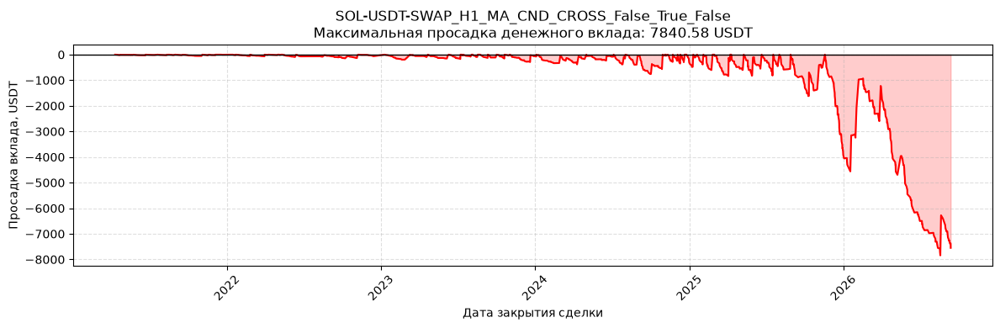

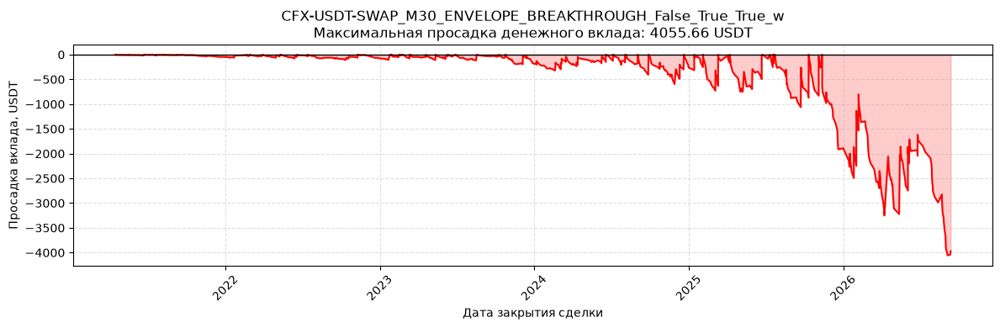

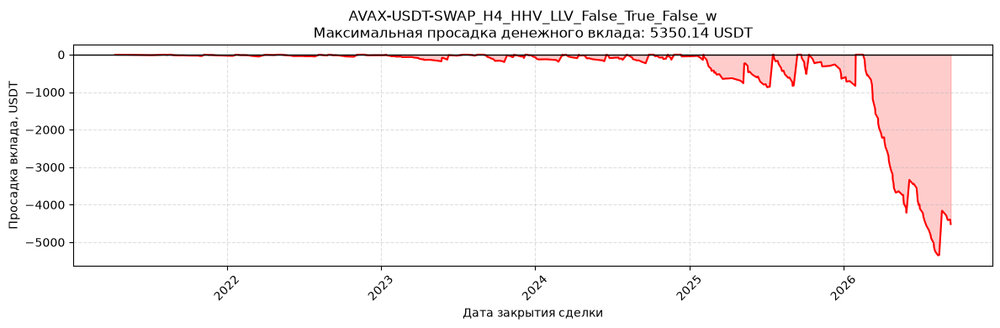

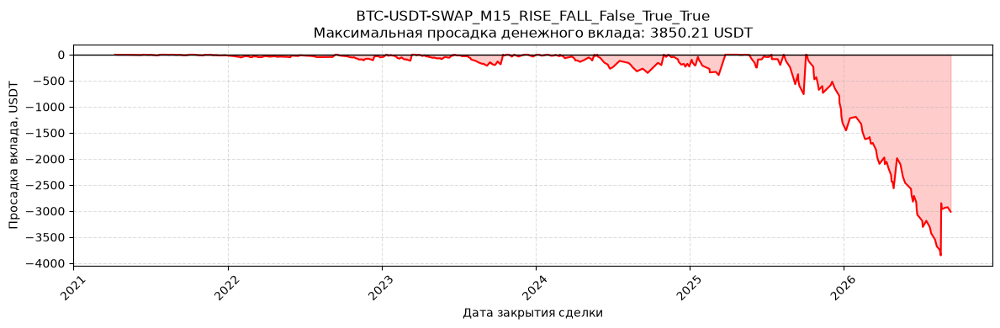

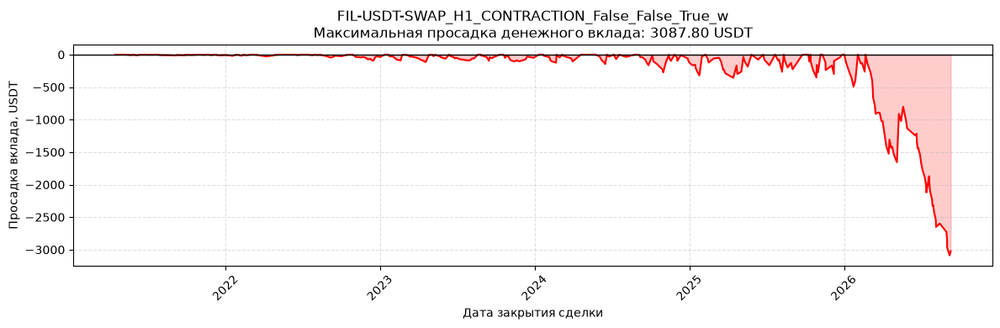

...

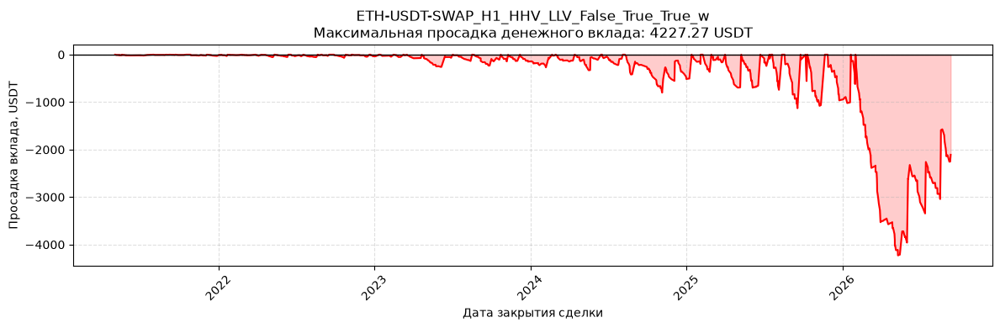

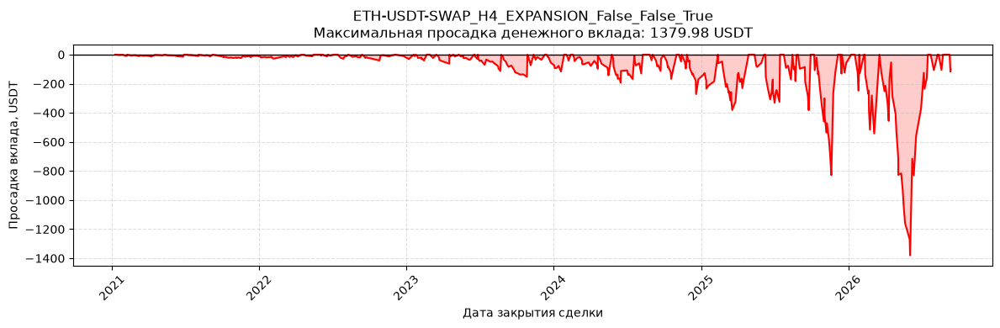

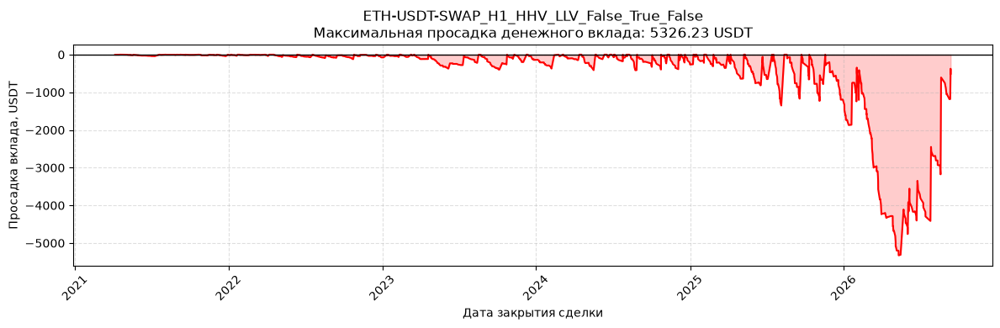

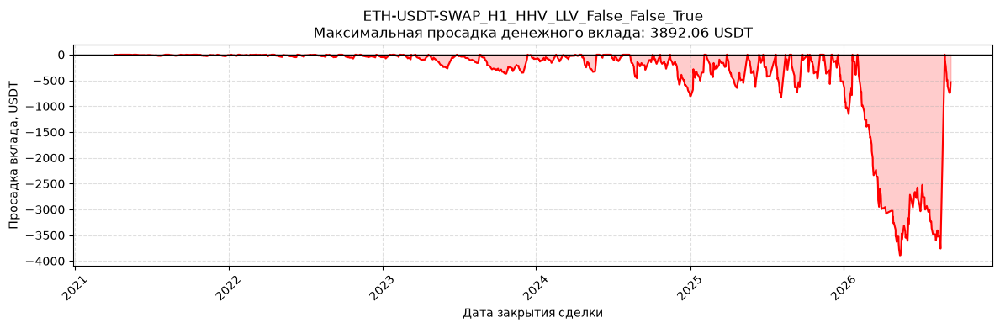

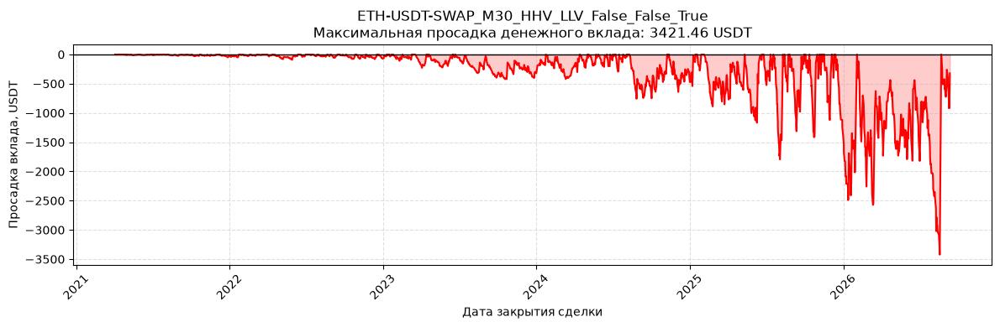

In [45]:
for strategy_name in all_metrics.index:
    drawdown = strategy_event_drawdown.xs(strategy_name, level='strategy_name')
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(drawdown.index, drawdown, color='red')
    ax.fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.2)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(title=f'{strategy_name}\nМаксимальная просадка денежного вклада: {all_metrics.loc[strategy_name, "max_drawdown_usdt"]:.2f} USDT', xlabel='Дата закрытия сделки', ylabel='Просадка вклада, USDT')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.4, linestyle='--')
    plt.tight_layout()
    plt.show()
    plt.close(fig)

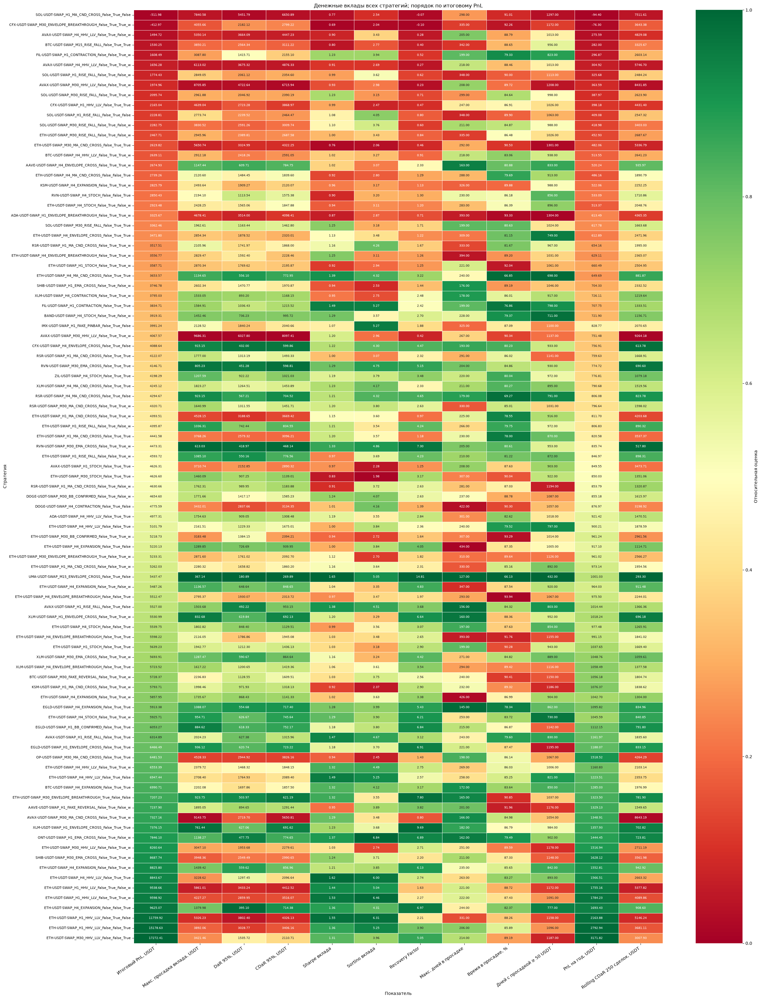

In [48]:
heatmap_data = all_metrics.sort_values('net_pnl_usdt')[metrics].replace([np.inf, -np.inf], np.nan)
heatmap_scaled = heatmap_data.rank(pct=True)
heatmap_scaled[risk_metrics] = heatmap_data[risk_metrics].rank(pct=True, ascending=False)
heatmap_scaled = heatmap_scaled.rename(columns=metric_names)
annotations = heatmap_data.rename(columns=metric_names)
plt.figure(figsize=(26, max(12, len(heatmap_data) * 0.35)))
sns.heatmap(heatmap_scaled, annot=annotations, fmt='.2f', mask=annotations.isna(), cmap='RdYlGn', vmin=0, vmax=1, linewidths=0.4, annot_kws={'fontsize': 7}, cbar_kws={'label': 'Относительная оценка'})
plt.title(f'Денежные вклады всех стратегий; порядок по итоговому PnL')
plt.xlabel('Показатель')
plt.ylabel('Стратегия')
plt.xticks(rotation=35, ha='right')
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

In [47]:
worst_metrics = all_metrics.loc[worst_strategies, metrics]
display(worst_metrics.round(3))

,net_pnl_usdt,max_drawdown_usdt,DaR_95_usdt,CDaR_95_usdt,Sharpe_contribution,Sortino_contribution,pnl_drawdown_ratio,max_drawdown_duration_days,time_in_drawdown_calendar_pct,serious_drawdown_days,annualized_pnl_usdt,rolling_cdar_250_usdt
strategy_name,,,,,,,,,,,,
SOL-USDT-SWAP_H1_MA_CND_CROSS_False_True_False,-511.983,7840.584,5451.789,6650.885,0.774,2.541,-0.065,298.0,91.015,1297.0,-94.398,7511.606
CFX-USDT-SWAP_M30_ENVELOPE_BREAKTHROUGH_False_True_True_w,-412.972,4055.657,2182.122,2799.217,0.689,2.039,-0.102,335.0,92.261,1172.0,-76.296,3643.383
AVAX-USDT-SWAP_H4_HHV_LLV_False_True_False_w,1494.725,5350.138,3664.093,4447.228,0.901,3.428,0.279,205.0,88.794,1013.0,275.592,4829.082
BTC-USDT-SWAP_M15_RISE_FALL_False_True_True,1530.250,3850.208,2564.338,3111.223,0.804,2.773,0.397,342.0,88.648,956.0,282.000,3325.666
FIL-USDT-SWAP_H1_CONTRACTION_False_False_True_w,1608.488,3087.803,1415.710,2155.104,1.232,3.943,0.521,199.0,79.333,823.0,296.867,2603.137


Задать вопрос: 

почему у этих стратегий такой низкий вклад (`profit_eq_pc`) в общую торговлю, если у части из них достаточно неплохие данные по риск-метрикам в сравнении с другими стратегиями чей вклад оказался больше? 

### По метрикам (смотрел вывод heatmap) - субъективно

- BTC-USDT-SWAP_M15_RISE_FALL_False_True_True - у него также малый вклад `profit_eq_pc`
- SHIB-USDT-SWAP_H1_EMA_CROSS_False_True_False_w - у него также малый вклад `profit_eq_pc`
- CFX-USDT-SWAP_M30_ENVELOPE_BREAKTHROUGH_False_True_True_w - у него также малый вклад `profit_eq_pc`
- XLM-USDT-SWAP_H4_CONTRACTION_False_True_True_w (?) - у него также малый вклад `profit_eq_pc`
- ETH-USDT-SWAP_H4_STOCH_False_True_False_w (?)
- ETH-USDT-SWAP_M30_RISE_FALL_False_True_False_w (??)
- AVAX-USDT-SWAP_H4_HHV_LLV_False_True_False_w 
- ADA-USDT-SWAP_H1_ENVELOPE_BREAKTHROUGH_False_True_True_w
- AVAX-USDT-SWAP_H4_HHV_LLV_False_True_True_w
- AVAX-USDT-SWAP_HI_STOCH_False_True_True
- CFX-USDT-SWAP_H1_HHV_LLV_False_True_True (?)
- OP-USDT-SWAP_M30_MA_CND_CROSS_False_True_True (?)
- ETH-USDT-SWAP_M30_MA_CND_CROSS_False_True_True
- KSM-USDT-SWAP_H1_MA_CND_CROSS_False_True_True_w (??)
- SOL-USDT-SWAP_H1_MA_CND_CROSS_False_True_False
- ETH-USDT-SWAP_H1_MA_CND_CROSS_False_True_True_w (?)
- AVAX-USDT-SWAP_M30_HHV_LLV_False_False_True_w
- AVAX-USDT-SWAP_M30_HHV_LLV_False_True_True_w
- AVAX-USDT-SWAP_M30_MA_CND_CROSS_False_True_True_w
- ETH-USDT-SWAP_H1_HHV_LLV_False_True_False_w (???)
- ETH-USDT-SWAP_H1_HHV_LLV_False_False_True (???)
- ETH-USDT-SWAP_H1_HHV_LLV_False_True_True_w (???)
- ETH-USDT-SWAP_M30_HHV_LLV_False_False_True (???)
- ETH-USDT-SWAP_H1_HHV_LLV_False_True_False (???)

## Идея: отключать не все стратегии в период просадок а только выделенные